# Data Cleaning: Multi-Hospital Lab Results
**Fouzia Khan** | Data Analytics | Oasis Infobyte SIP, Level 1, Task 3

Goal: turn a messy lab-results dataset into a clean, analysis-ready one.

In [13]:
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ZIP_PATH = Path("/content/drive/MyDrive/data-cleanig.zip")
WORK_DIR = Path("/content/data")
OUTPUT_PATH = Path("/content/cleaned_multi_hospital_lab_results.csv")

TEST_NAME_MAP = {
    "glucose": "Glucose", "fasting glucose": "Glucose", "blood sugar": "Glucose",
    "hba1c": "HbA1c", "hemoglobin a1c": "HbA1c", "glycated hemoglobin": "HbA1c",
    "cholesterol": "Total Cholesterol", "serum cholesterol": "Total Cholesterol", "total chol": "Total Cholesterol",
}
TARGET_UNIT = {"Glucose": "mg/dL", "Total Cholesterol": "mg/dL", "HbA1c": "%"}
MMOL_TO_MGDL = {"Glucose": 18.016, "Total Cholesterol": 38.67}
PLAUSIBLE_LIMITS = {"Glucose": (20, 800), "Total Cholesterol": (50, 600), "HbA1c": (3, 20)}


def show(data, title=""):
    """Display a DataFrame as a styled table."""
    if title:
        display(Markdown(f"**{title}**"))
    styled = (data.style.hide(axis="index").format(precision=2, na_rep="-")
              .set_table_styles([{"selector": "th", "props": [("background-color", "#1f4e79"),
                                                              ("color", "white"), ("text-align", "left")]}]))
    display(styled)

In [14]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # not running in Colab

csv_path = WORK_DIR / "multi_hospital_lab_results.csv"
if not csv_path.exists():
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    zipfile.ZipFile(ZIP_PATH).extractall(WORK_DIR)

df_raw = pd.read_csv(csv_path)
df = df_raw.copy()
show(df_raw.head(), "Raw data (first 5 rows)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Raw data (first 5 rows)**

hospital,patient_id,test_name,test_value,unit,reference_range,collection_date
Hospital_A,1966,Fasting Glucose,8.56,mmol/L,70-99,2025-08-15
Hospital_C,1826,Glucose,-999,mmol/L,70-99,2024-07-04
Hospital_A,1606,Cholesterol,6.45,mmol/L,125-200,2024-11-13
Hospital_B,1277,Fasting Glucose,-999,mmol/L,3.9-5.5,2024-04-29
Hospital_A,1841,Serum Cholesterol,5.61,mmol/L,<200,2024-08-05


## 1. Data Quality Report

In [15]:
raw_text = df_raw["test_value"].astype("string").str.strip().str.lower()
before = {
    "rows": len(df_raw),
    "nulls": int(df_raw["test_value"].isna().sum()),
    "hidden": int(raw_text.isin(["-999", "not collected"]).sum()),
    "duplicates": int(df_raw.duplicated().sum()),
    "names": df_raw["test_name"].nunique(),
    "units": df_raw["unit"].nunique(),
}
show(pd.DataFrame({
    "Metric": ["Rows", "Null test_value", "Hidden missing (-999 / not collected)",
               "Duplicate rows", "Distinct test names", "Distinct units"],
    "Count": list(before.values()),
}), "Quality report")

show(pd.DataFrame({"Column": df_raw.columns, "Dtype": df_raw.dtypes.astype(str).values,
                   "Nulls": df_raw.isna().sum().values, "Unique values": df_raw.nunique().values}), "Columns")

numeric = pd.to_numeric(df_raw["test_value"], errors="coerce").replace(-999, np.nan)
show(numeric.groupby(df_raw["unit"]).agg(["min", "max"]).reset_index().rename(columns={"unit": "Unit", "min": "Min", "max": "Max"}),
     "Value range per unit (note the extreme mmol/L maximum)")

**Quality report**

Metric,Count
Rows,1500
Null test_value,39
Hidden missing (-999 / not collected),62
Duplicate rows,0
Distinct test names,9
Distinct units,3


**Columns**

Column,Dtype,Nulls,Unique values
hospital,object,0,3
patient_id,int64,0,760
test_name,object,0,9
test_value,object,39,800
unit,object,0,3
reference_range,object,0,9
collection_date,object,0,646


**Value range per unit (note the extreme mmol/L maximum)**

Unit,Min,Max
%,4.50,10.50
mg/dL,71.37,298.22
mmol/L,3.89,1860.00


## 2. Missing Values
Missing results hide as real nulls, the code `-999` and the text `not collected`. They are converted to `NaN` and the rows are **dropped**, not imputed: a lab result is a patient measurement, and filling it with an average would invent a clinical value that was never measured.

The other columns (`hospital`, `patient_id`, `test_name`, `unit`, `reference_range`, `collection_date`) contain no nulls, so no action is needed for them.

In [16]:
raw_text = df["test_value"].astype("string").str.strip().str.lower()
causes = pd.DataFrame({
    "Cause": ["Real null", "Code -999", "Text 'not collected'"],
    "Rows": [int(df["test_value"].isna().sum()), int((raw_text == "-999").sum()), int((raw_text == "not collected").sum())],
})
causes.loc[len(causes)] = ["Total missing", causes["Rows"].sum()]
show(causes, "Missing values by cause")

df["test_value"] = pd.to_numeric(df["test_value"].mask(raw_text.isin(["-999", "not collected"])), errors="coerce")
rows_missing = int(df["test_value"].isna().sum())
df = df.dropna(subset=["test_value"]).reset_index(drop=True)
print(f"Rows dropped: {rows_missing} | Rows remaining: {len(df)}")

**Missing values by cause**

Cause,Rows
Real null,39
Code -999,36
Text 'not collected',26
Total missing,101


Rows dropped: 101 | Rows remaining: 1399


## 3. Standardisation
Test names, units, reference ranges and dates are made consistent. Glucose and cholesterol are converted from mmol/L to mg/dL so all values per test share one unit.

In [17]:
names_before = df["test_name"].value_counts().rename_axis("Original name").reset_index(name="Rows")
names_before["Standard name"] = names_before["Original name"].str.strip().str.lower().map(TEST_NAME_MAP)
show(names_before[["Standard name", "Original name", "Rows"]].sort_values(["Standard name", "Original name"]), "Test names (9 to 3)")

df["test_name"] = df["test_name"].str.strip().str.lower().map(TEST_NAME_MAP)
assert df["test_name"].notna().all(), "Unmapped test name found"

df["original_value"], df["original_unit"] = df["test_value"], df["unit"]
to_convert = (df["unit"] == "mmol/L") & df["test_name"].isin(MMOL_TO_MGDL)
df.loc[to_convert, "test_value"] *= df.loc[to_convert, "test_name"].map(MMOL_TO_MGDL)
df["unit"] = df["test_name"].map(TARGET_UNIT)
df["test_value"] = df["test_value"].round(2)

conversion = (df.groupby(["test_name", "original_unit", "unit"]).size().reset_index(name="Rows")
              .rename(columns={"test_name": "Test", "original_unit": "Original unit", "unit": "Standard unit"}))
show(conversion, "Unit conversion")

**Test names (9 to 3)**

Standard name,Original name,Rows
Glucose,Blood Sugar,157
Glucose,Fasting Glucose,148
Glucose,Glucose,143
HbA1c,Glycated Hemoglobin,153
HbA1c,HbA1c,161
HbA1c,Hemoglobin A1c,164
Total Cholesterol,Cholesterol,167
Total Cholesterol,Serum Cholesterol,166
Total Cholesterol,Total Chol,140


**Unit conversion**

Test,Original unit,Standard unit,Rows
Glucose,mg/dL,mg/dL,219
Glucose,mmol/L,mg/dL,229
HbA1c,%,%,478
Total Cholesterol,mg/dL,mg/dL,232
Total Cholesterol,mmol/L,mg/dL,241


In [18]:
RANGE_PATTERN = re.compile(r"(\d+(?:\.\d+)?)\s*-\s*(\d+(?:\.\d+)?)")
UPPER_PATTERN = re.compile(r"<\s*(\d+(?:\.\d+)?)")


def parse_range(text):
    """Convert '70-99', '<200' or 'Normal: <100' into (low, high)."""
    match = RANGE_PATTERN.search(text)
    if match:
        return float(match.group(1)), float(match.group(2))
    match = UPPER_PATTERN.search(text)
    return (0.0, float(match.group(1))) if match else (np.nan, np.nan)


bounds = df["reference_range"].apply(parse_range)
df["reference_low"], df["reference_high"] = bounds.str[0], bounds.str[1]

# Glucose/cholesterol ranges with an upper bound below 20 are written in mmol/L.
in_mmol = df["test_name"].isin(MMOL_TO_MGDL) & (df["reference_high"] < 20)
factors = df.loc[in_mmol, "test_name"].map(MMOL_TO_MGDL)
df.loc[in_mmol, ["reference_low", "reference_high"]] = (
    df.loc[in_mmol, ["reference_low", "reference_high"]].mul(factors, axis=0).round(0).to_numpy())

show(df.groupby(["test_name", "reference_range"])[["reference_low", "reference_high"]].first().reset_index()
     .rename(columns={"test_name": "Test", "reference_range": "Raw range", "reference_low": "Low", "reference_high": "High"}),
     "Reference ranges as numbers")

df["collection_date"] = pd.to_datetime(df["collection_date"], errors="coerce")
invalid_dates = int(df["collection_date"].isna().sum())
df = df.dropna(subset=["collection_date"]).reset_index(drop=True)
print(f"Invalid dates removed: {invalid_dates} | Date range: {df['collection_date'].min():%Y-%m-%d} to {df['collection_date'].max():%Y-%m-%d}")

**Reference ranges as numbers**

Test,Raw range,Low,High
Glucose,3.9-5.5,70.00,99.00
Glucose,70-99,70.00,99.00
Glucose,Normal: <100,0.00,100.00
HbA1c,4.0-5.6%,4.00,5.60
HbA1c,<5.7%,0.00,5.70
HbA1c,Normal < 6,0.00,6.00
Total Cholesterol,125-200,125.00,200.00
Total Cholesterol,3.2-5.2,124.00,201.00
Total Cholesterol,<200,0.00,200.00


Invalid dates removed: 0 | Date range: 2024-03-26 to 2026-03-26


## 4. Duplicates
Exact duplicates and repeated records (same hospital, patient, test and date). This runs after standardisation so that synonyms of one test are recognised.

In [19]:
key = ["hospital", "patient_id", "test_name", "collection_date"]
exact_dups = int(df.duplicated().sum())
df = df.drop_duplicates()
key_dups = int(df.duplicated(subset=key).sum())
df = df.drop_duplicates(subset=key).reset_index(drop=True)

show(pd.DataFrame({"Check": ["Exact duplicates", "Repeated records (hospital + patient + test + date)"],
                   "Rows removed": [exact_dups, key_dups]}), "Duplicates")

**Duplicates**

Check,Rows removed
Exact duplicates,0
Repeated records (hospital + patient + test + date),0


## 5. Outliers (IQR)
Outliers are found per test with the IQR rule (values outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR). **Impossible values** (such as glucose of 500 mmol/L, about 9,000 mg/dL) are removed as data-entry errors. Plausible extreme values would be kept, because in healthcare a high result can be a real patient.

In [20]:
grouped = df.groupby("test_name")["test_value"]
q1 = grouped.transform(lambda s: s.quantile(0.25))
q3 = grouped.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df["is_outlier"] = (df["test_value"] < q1 - 1.5 * iqr) | (df["test_value"] > q3 + 1.5 * iqr)

limits = grouped.quantile([0.25, 0.75]).unstack()
limits.columns = ["Q1", "Q3"]
limits["Lower limit"] = limits["Q1"] - 1.5 * (limits["Q3"] - limits["Q1"])
limits["Upper limit"] = limits["Q3"] + 1.5 * (limits["Q3"] - limits["Q1"])
limits["Outliers"] = df.groupby("test_name")["is_outlier"].sum()
show(limits.reset_index().rename(columns={"test_name": "Test"}), "IQR limits and outlier count")

low = df["test_name"].map(lambda t: PLAUSIBLE_LIMITS[t][0])
high = df["test_name"].map(lambda t: PLAUSIBLE_LIMITS[t][1])
df["is_impossible"] = ~df["test_value"].between(low, high)
show(df.loc[df["is_outlier"], ["hospital", "patient_id", "test_name", "original_value", "original_unit", "test_value", "unit"]]
     .rename(columns={"test_name": "Test", "original_value": "Original value", "original_unit": "Original unit",
                      "test_value": "Standard value"}), "Flagged outliers")

**IQR limits and outlier count**

Test,Q1,Q3,Lower limit,Upper limit,Outliers
Glucose,104.21,158.54,22.72,240.03,7
HbA1c,6.00,9.00,1.50,13.50,0
Total Cholesterol,181.36,257.14,67.69,370.81,0


**Flagged outliers**

hospital,patient_id,Test,Original value,Original unit,Standard value,unit
Hospital_B,1567,Glucose,500.00,mmol/L,9008.00,mg/dL
Hospital_C,1834,Glucose,500.00,mmol/L,9008.00,mg/dL
Hospital_B,1714,Glucose,500.00,mmol/L,9008.00,mg/dL
Hospital_B,1932,Glucose,1860.00,mmol/L,33509.76,mg/dL
Hospital_A,1189,Glucose,500.00,mmol/L,9008.00,mg/dL
Hospital_A,1074,Glucose,500.00,mmol/L,9008.00,mg/dL
Hospital_A,1981,Glucose,500.00,mmol/L,9008.00,mg/dL


Impossible values removed: 7 | Plausible outliers kept: 0 | Rows remaining: 1392


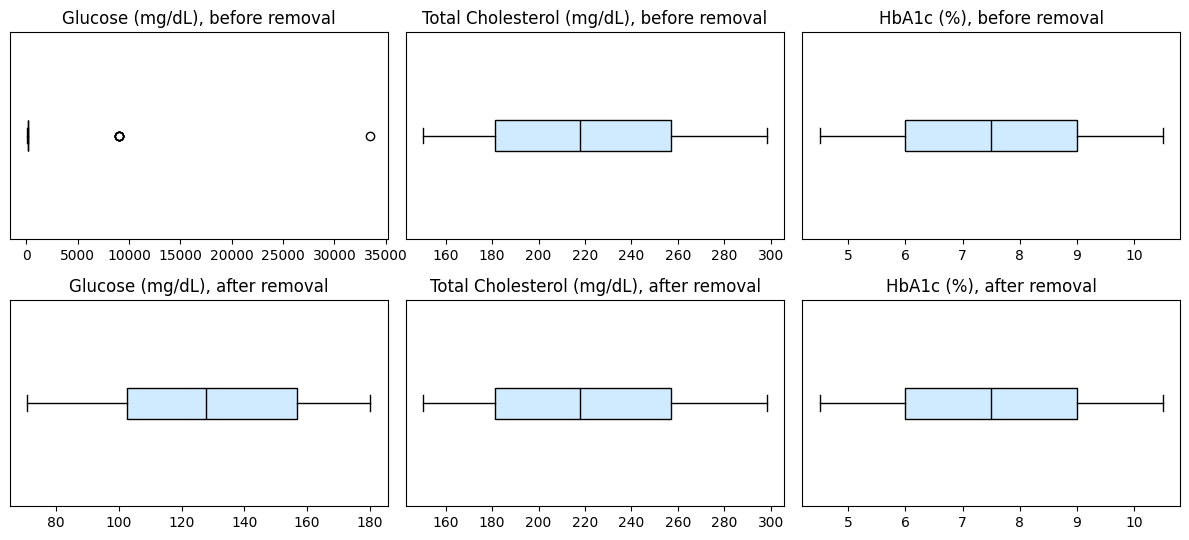

In [21]:
df_with_outliers = df.copy()
rows_impossible = int(df["is_impossible"].sum())
kept_outliers = int((df["is_outlier"] & ~df["is_impossible"]).sum())
df = df[~df["is_impossible"]].reset_index(drop=True)
print(f"Impossible values removed: {rows_impossible} | Plausible outliers kept: {kept_outliers} | Rows remaining: {len(df)}")

fig, axes = plt.subplots(2, 3, figsize=(12, 5.5))
for col, test in enumerate(TARGET_UNIT):
    for row, (frame, label) in enumerate([(df_with_outliers, "before"), (df, "after")]):
        axes[row, col].boxplot(frame.loc[frame["test_name"] == test, "test_value"], vert=False, patch_artist=True,
                               boxprops=dict(facecolor="#d0ebff"), medianprops=dict(color="black"))
        axes[row, col].set_title(f"{test} ({TARGET_UNIT[test]}), {label} removal")
        axes[row, col].set_yticks([])
plt.tight_layout()
plt.show()

## 6. Data Types
IDs become string, repeating text becomes category, results become float. Helper columns are dropped.

In [22]:
df = df.drop(columns=["is_outlier", "is_impossible", "reference_range"])
df = df.astype({"hospital": "category", "patient_id": "string", "test_name": "category", "unit": "category",
                "original_unit": "category", "test_value": "float64", "original_value": "float64",
                "reference_low": "float64", "reference_high": "float64"})

df_clean = df[["hospital", "patient_id", "test_name", "test_value", "unit", "reference_low", "reference_high",
               "collection_date", "original_value", "original_unit"]].sort_values(["collection_date", "patient_id"]).reset_index(drop=True)

show(pd.DataFrame({"Column": df_clean.columns, "Dtype": df_clean.dtypes.astype(str).values}), "Final data types")
show(df_clean.head(), "Cleaned data (first 5 rows)")

**Final data types**

Column,Dtype
hospital,category
patient_id,string
test_name,category
test_value,float64
unit,category
reference_low,float64
reference_high,float64
collection_date,datetime64[ns]
original_value,float64
original_unit,category


**Cleaned data (first 5 rows)**

hospital,patient_id,test_name,test_value,unit,reference_low,reference_high,collection_date,original_value,original_unit
Hospital_C,1402,HbA1c,8.30,%,4.00,5.60,2024-03-26 00:00:00,8.30,%
Hospital_C,1873,Total Cholesterol,158.16,mg/dL,0.00,200.00,2024-03-26 00:00:00,4.09,mmol/L
Hospital_B,1279,Glucose,107.74,mg/dL,70.00,99.00,2024-03-27 00:00:00,5.98,mmol/L
Hospital_C,1377,HbA1c,9.20,%,4.00,5.60,2024-03-27 00:00:00,9.20,%
Hospital_C,1623,Glucose,176.20,mg/dL,70.00,99.00,2024-03-27 00:00:00,9.78,mmol/L


## 7. Before vs. After

In [23]:
def dtype_accuracy(data, expected):
    """Count columns whose dtype matches their logical type."""
    checks = {
        "text": lambda s: pd.api.types.is_string_dtype(s) or isinstance(s.dtype, pd.CategoricalDtype),
        "numeric": pd.api.types.is_numeric_dtype,
        "datetime": pd.api.types.is_datetime64_any_dtype,
    }
    return f"{sum(checks[kind](data[col]) for col, kind in expected.items())}/{len(expected)}"


expected_before = {"hospital": "text", "patient_id": "text", "test_name": "text", "test_value": "numeric",
                   "unit": "text", "reference_range": "text", "collection_date": "datetime"}
expected_after = {"hospital": "text", "patient_id": "text", "test_name": "text", "test_value": "numeric",
                  "unit": "text", "reference_low": "numeric", "reference_high": "numeric", "collection_date": "datetime"}

summary = pd.DataFrame({
    "Metric": ["Row count", "Null test_value", "Hidden placeholders", "Duplicate rows",
               "Distinct test names", "Distinct units", "Dtype accuracy"],
    "Before": [before["rows"], before["nulls"], before["hidden"], before["duplicates"],
               before["names"], before["units"], dtype_accuracy(df_raw, expected_before)],
    "After": [len(df_clean), int(df_clean["test_value"].isna().sum()), 0, int(df_clean.duplicated().sum()),
              df_clean["test_name"].nunique(), df_clean["unit"].nunique(), dtype_accuracy(df_clean, expected_after)],
}).astype({"Before": "string", "After": "string"})
show(summary, "Before vs. after cleaning")

**Before vs. after cleaning**

Metric,Before,After
Row count,1500,1392
Null test_value,39,0
Hidden placeholders,62,0
Duplicate rows,0,0
Distinct test names,9,3
Distinct units,3,2
Dtype accuracy,4/7,8/8


## 8. Save

In [24]:
df_clean.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(df_clean):,} rows x {df_clean.shape[1]} columns to {OUTPUT_PATH}")

Saved 1,392 rows x 10 columns to /content/cleaned_multi_hospital_lab_results.csv


## Conclusion
- Hidden missing values (`-999`, `not collected`) were uncovered and removed, not imputed.
- 9 test names became 3, and mixed units were converted to one unit per test.
- 7 impossible glucose values were removed as data-entry errors.
- All columns now have correct data types; the cleaned CSV is ready for analysis.